In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Roman-Cuts


In [2]:
import os
import asdf
import numpy as np
import matplotlib.pyplot as plt

from astroquery.mast import MastMissions, Observations
from roman_cuts.com import query_mast_files, make_cutout
from roman_cuts.com import save_to_asdf
from astropy.visualization import simple_norm

from dotenv import load_dotenv

# loading teams CRDS cache and MyST token
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ["MAST_API_TOKEN"]

In [3]:
mission = MastMissions(mission="roman")
mission.login(token=token)
Observations.enable_cloud_dataset()

INFO: MAST API token accepted, welcome Jorge Martinez-Palomera [astroquery.mast.auth]
INFO: Using the S3 STScI public dataset [astroquery.mast.cloud]


In [4]:
pid = 1055
detector = 4
ra = 250.630997
dec = 36.253313
filter = "F146"
size = (15, 15)

In [5]:
# 2. Find L2 files for a specific field
products_l2, _ = query_mast_files(
    program_id=pid,
    detector=detector,
    filter_name=filter,
    # observation=13,  # primary sky-field identifier
    mission=mission,
    file_type="l2",
)
print(f"{len(products_l2)} files found")
products_l2

INFO: 13569 of 18928 products were duplicates. Only returning 5359 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
728 files found


product_key,access,dataset,instrument_name,filters,filename,uri,authz_primary_identifier,authz_secondary_identifier,file_suffix,suffix_description,category,size,type,obs_collection,project,mrp,calibration_software_version,crds_context_used,crds_software_version,edp_url
str85,str6,str36,str3,str4,str48,str85,str48,str48,str8,str1,str11,int64,str18,str1,str1,bool,str5,str15,str6,str92
r0105501001001004001_0005_wfi04_f146_r0105501001001004001_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004001_0005_wfi04_f146,WFI,F146,r0105501001001004001_0005_wfi04_f146_cal.asdf,r0105501001001004001_0005_wfi04_f146/r0105501001001004001_0005_wfi04_f146_cal.asdf,r0105501001001004001_0005_wfi04_f146_cal.asdf,r0105501001001004001_0005_wfi04_f146_cal.asdf,_cal,,2,212950461,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=04:07:10&end_date=2026-10-02&end_time=04:08:20
r0105501001001004008_0001_wfi04_f146_r0105501001001004008_0001_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004008_0001_wfi04_f146,WFI,F146,r0105501001001004008_0001_wfi04_f146_cal.asdf,r0105501001001004008_0001_wfi04_f146/r0105501001001004008_0001_wfi04_f146_cal.asdf,r0105501001001004008_0001_wfi04_f146_cal.asdf,r0105501001001004008_0001_wfi04_f146_cal.asdf,_cal,,2,212957847,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=05:03:15&end_date=2026-10-02&end_time=05:04:24
r0105501001001004011_0003_wfi04_f146_r0105501001001004011_0003_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004011_0003_wfi04_f146,WFI,F146,r0105501001001004011_0003_wfi04_f146_cal.asdf,r0105501001001004011_0003_wfi04_f146/r0105501001001004011_0003_wfi04_f146_cal.asdf,r0105501001001004011_0003_wfi04_f146_cal.asdf,r0105501001001004011_0003_wfi04_f146_cal.asdf,_cal,,2,212939509,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=05:32:23&end_date=2026-10-02&end_time=05:33:33
r0105501001001004011_0005_wfi04_f146_r0105501001001004011_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004011_0005_wfi04_f146,WFI,F146,r0105501001001004011_0005_wfi04_f146_cal.asdf,r0105501001001004011_0005_wfi04_f146/r0105501001001004011_0005_wfi04_f146_cal.asdf,r0105501001001004011_0005_wfi04_f146_cal.asdf,r0105501001001004011_0005_wfi04_f146_cal.asdf,_cal,,2,212925246,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=05:35:08&end_date=2026-10-02&end_time=05:36:17
r0105501001001006002_0002_wfi04_f146_r0105501001001006002_0002_wfi04_f146_cal.asdf,PUBLIC,r0105501001001006002_0002_wfi04_f146,WFI,F146,r0105501001001006002_0002_wfi04_f146_cal.asdf,r0105501001001006002_0002_wfi04_f146/r0105501001001006002_0002_wfi04_f146_cal.asdf,r0105501001001006002_0002_wfi04_f146_cal.asdf,r0105501001001006002_0002_wfi04_f146_cal.asdf,_cal,,2,212947295,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=07:42:45&end_date=2026-10-02&end_time=07:43:55
r0105501001001006004_0004_wfi04_f146_r0105501001001006004_0004_wfi04_f146_cal.asdf,PUBLIC,r0105501001001006004_0004_wfi04_f146,WFI,F146,r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146/r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146_cal.asdf,_cal,,2,212933296,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=08:03:03&end_date=2026-10-02&end_time=08:04:13
r0105501001001007001_0001_wfi04_f146_r0105501001001007001_0001_wfi04_f146_cal.asdf,PUBLIC,r0105501001001007001_0001_wfi04_f146,WFI,F146,r0105501001001007001_0001_wfi04_f146_cal.asdf,r0105501001001007001_0001_wfi04_f146/r0105501001001007001_0001_wfi04_f146_cal.asdf,r0105501001001007001_0001_wfi04_f146_cal.asdf,r0105501001001007001_0001_wfi04_f146_cal.asdf,_cal,,2,212944735,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=09:18:01&end_date=2026-10-02&end_time=09:19:11
r0105501001001007009_00

In [ ]:
l2_sortidx = np.argsort(products_l2["dataset"].value)
products_l2 = products_l2[l2_sortidx]

# 3. Extract cutouts
cube, meta, gwcss = make_cutout(
    products_l2["filename"].tolist()[:100],
    ra=ra,
    dec=dec,
    size=size,
    mission=mission,
    lite=False,
    n_workers=4,
)

Extracting cutouts:   0%|          | 0/100 [00:00<?, ?file/s]

In [7]:
meta

,input_position_original,origin_original,input_position_cutout,bbox_original,effective_exposure_time,exposure_time,frame_time,start_time,end_time,exposure,observation,observation_id,visit,detector,optical_element,mid_time,ra_target,dec_target
0,"(2947.467668269529, 3307.996595074645)","(2940, 3301)","(7.4676682695289855, 6.996595074645029)","((3301, 3315), (2940, 2954))",66.41188,66.41188,3.16247,2026-10-02T03:49:13.842,2026-10-02T03:50:23.417,1.0,3.0,0105501001001003001031010001,1.0,WFI04,F146,2461315.659590619,250.630997,36.253313
1,"(2947.45925795225, 3307.9368086045015)","(2940, 3301)","(7.459257952250027, 6.936808604501493)","((3301, 3315), (2940, 2954))",66.41188,66.41188,3.16247,2026-10-02T03:50:35.906,2026-10-02T03:51:45.480,2.0,3.0,0105501001001003001031020002,1.0,WFI04,F146,2461315.660540428,250.630997,36.253313
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,"(2949.850728451188, 3311.4699382381373)","(2943, 3304)","(6.850728451187933, 7.469938238137274)","((3304, 3318), (2943, 2957))",66.41188,66.41188,3.16247,2026-10-02T06:08:57.625,2026-10-02T06:10:07.199,4.0,5.0,0105501001001005003031070004,3.0,WFI04,F146,2461315.756625139,250.630997,36.253313
96,"(2949.181620913482, 3311.39080622283)","(2942, 3304)","(7.18162091348222, 7.390806222830179)","((3304, 3318), (2942, 2956))",66.41188,66.41188,3.16247,2026-10-02T06:10:19.689,2026-10-02T06:11:29.263,5.0,5.0,0105501001001005003031090005,3.0,WFI04,F146,2461315.757574954,250.630997,36.253313
97,"(2948.829215209349, 3310.1118355903604)","(2942, 3303)","(6.829215209349059, 7.111835590360442)","((3303, 3317), (2942, 2956))",66.41188,66.41188,3.16247,2026-10-02T06:11:41.752,2026-10-02T06:12:51.326,6.0,5.0,0105501001001005003031110006,3.0,WFI04,F146,2461315.758524757,250.630997,36.253313
98,"(2947.9283969395046, 3310.054577000339)","(2941, 3303)","(6.928396939504637, 7.054577000339123)","((3303, 3317), (2941, 2955))",66.41188,66.41188,3.16247,2026-10-02T06:13:38.550,2026-10-02T06:14:48.124,1.0,5.0,0105501001001005004031010001,4.0,WFI04,F146,2461315.7598765856,250.630997,36.253313


In [8]:
cube.shape

(4, 100, 15, 15)

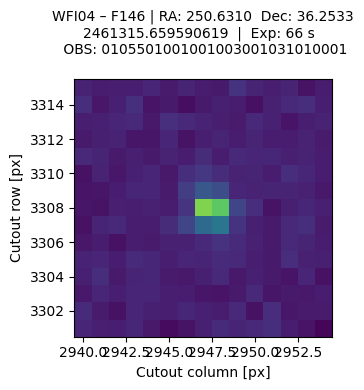

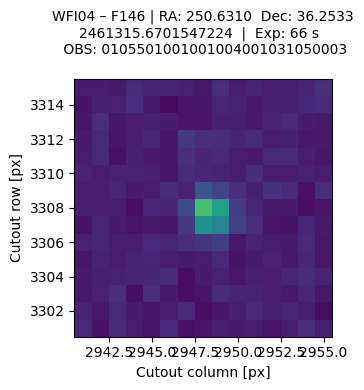

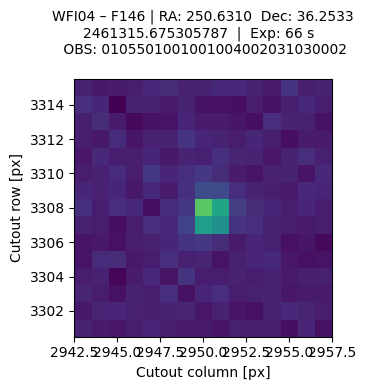

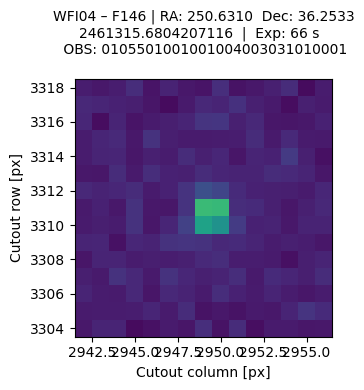

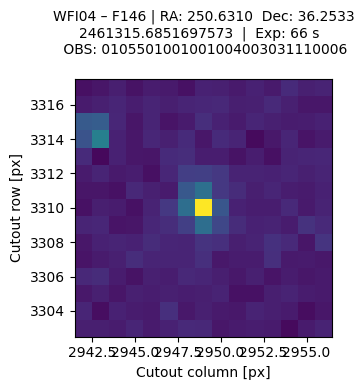

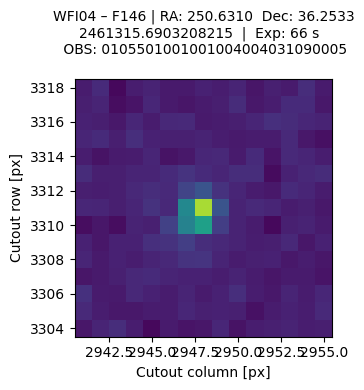

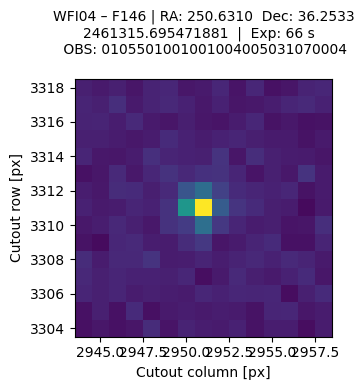

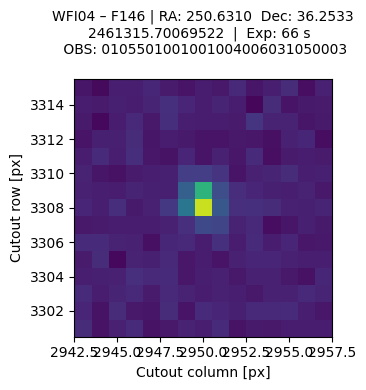

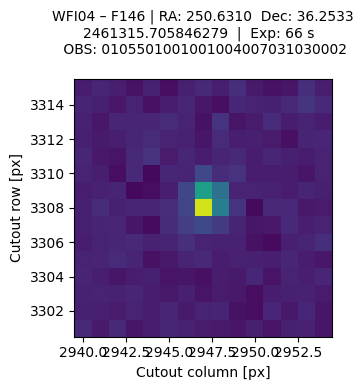

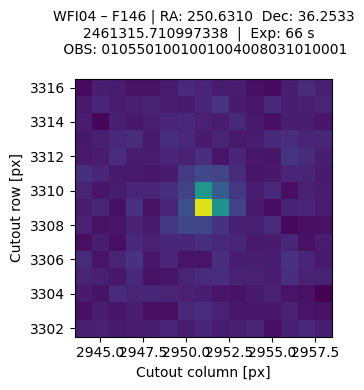

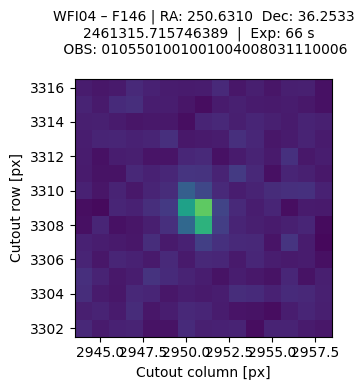

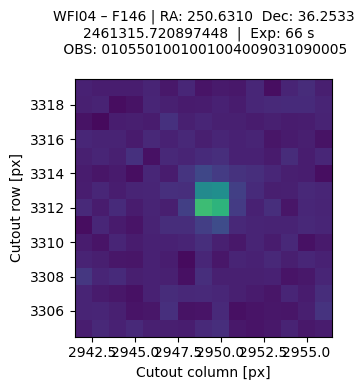

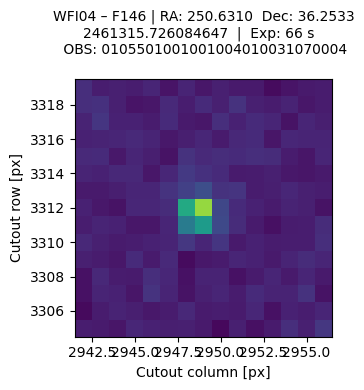

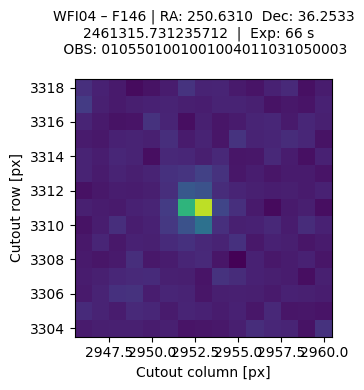

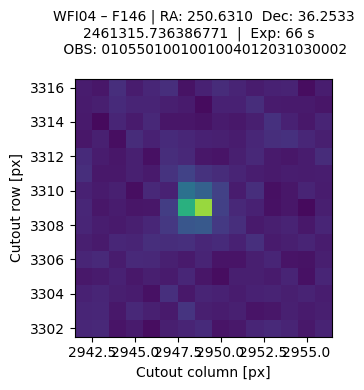

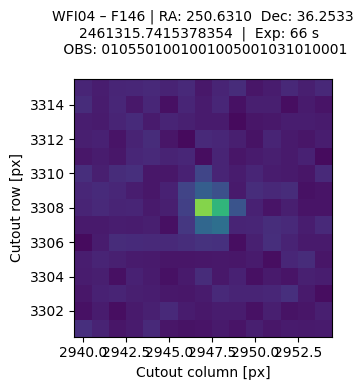

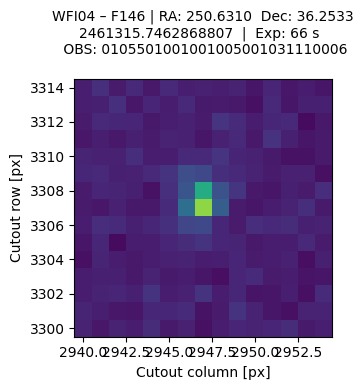

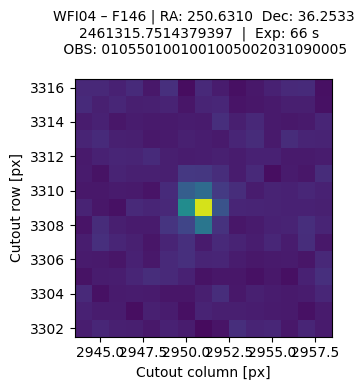

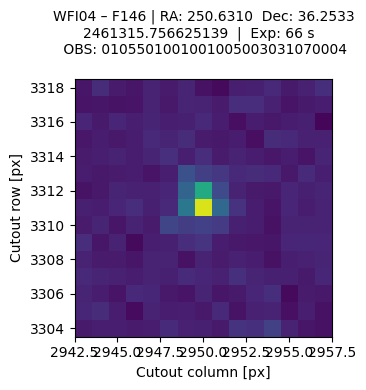

In [10]:
ext = 0

ny, nx = cube.shape[-2], cube.shape[-1]
norm = simple_norm(cube[ext].ravel(), stretch="linear", percent=99.9)

for k in range(0, len(cube[ext]), 5):
    if np.isnan(cube[ext][k]).all():
        continue
    origin = meta.loc[k, "origin_original"]  # (col_min, row_min) from Cutout2D
    xmin, ymin = int(origin[0]), int(origin[1])

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_title(
        f'{meta.loc[k, "detector"]} – {meta.loc[k, "optical_element"]} | '
        f'RA: {meta.loc[k, "ra_target"]:.4f}  Dec: {meta.loc[k, "dec_target"]:.4f}\n'
        f'{meta.loc[k, "mid_time"]}  |  '
        f'Exp: {meta.loc[k, "exposure_time"]:.0f} s  \n '
        f'OBS: {meta.loc[k, "observation_id"]}\n',
        fontsize=10,
    )
    ax.pcolormesh(
        np.arange(xmin, xmin + nx),
        np.arange(ymin, ymin + ny),
        cube[ext][k],
        norm=norm,
    )
    ax.set_aspect("equal", "box")
    ax.set_xlabel("Cutout column [px]")
    ax.set_ylabel("Cutout row [px]")
    plt.tight_layout()
    plt.show()


In [11]:
# 4. Save cutouts to a single ASDF
OUT_PATH = "/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts"
OUT_PATH = os.path.join(OUT_PATH, f"program_{pid}")
os.makedirs(OUT_PATH, exist_ok=True)

filename = os.path.join(OUT_PATH, f"cutouts_{pid}_{detector}_{filter}_{ra:.6f}_{dec:.6f}.asdf")
print(f"Saving cutouts to {filename}")

save_to_asdf(cube, meta, gwcss, filename)

Saving cutouts to /home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.630997_36.253313.asdf


In [15]:
load_tree = asdf.open(filename)

In [16]:
load_tree.info()

root (AsdfObject)
├─asdf_library (Software)
│ ├─author (str): The ASDF Developers
│ ├─homepage (str): http://github.com/asdf-format/asdf
│ ├─name (str): asdf
│ └─version (str): 5.2.0
├─history (dict)
│ └─extensions (list)
│   ├─[0] (ExtensionMetadata) ...
│   ├─[1] (ExtensionMetadata) ...
│   ├─[2] (ExtensionMetadata) ...
│   ├─[3] (ExtensionMetadata) ...
│   ├─[4] (ExtensionMetadata) ...
│   └─2 not shown
└─roman (dict)
  ├─data (NDArrayType) ...
  ├─dq (NDArrayType) ...
  ├─dumo (NDArrayType) ...
  ├─err (NDArrayType) ...
  ├─meta (dict) ...
  ├─quality (NDArrayType) ...
  ├─time (list) ...
  └─wcs (list) ...
Some nodes not shown.


In [ ]:
meta

: 

: 